In [1]:
import pandas as pd

In [26]:
def freight_loading():
    csv_path="train-test-exp.csv"
    return pd.read_csv(csv_path)

In [3]:
freight=freight_loading()
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## Understanding missing data and data types

In [4]:
freight.info()

<class 'pandas.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  str    
 1   pickup        48000 non-null  str    
 2   delivery      48000 non-null  str    
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  str    
 9   weight        47700 non-null  float64
 10  date          48000 non-null  str    
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), str(5)
memory usage: 5.1 MB


## Exploring data deeply to understand its distribution

In [5]:
%matplotlib inline

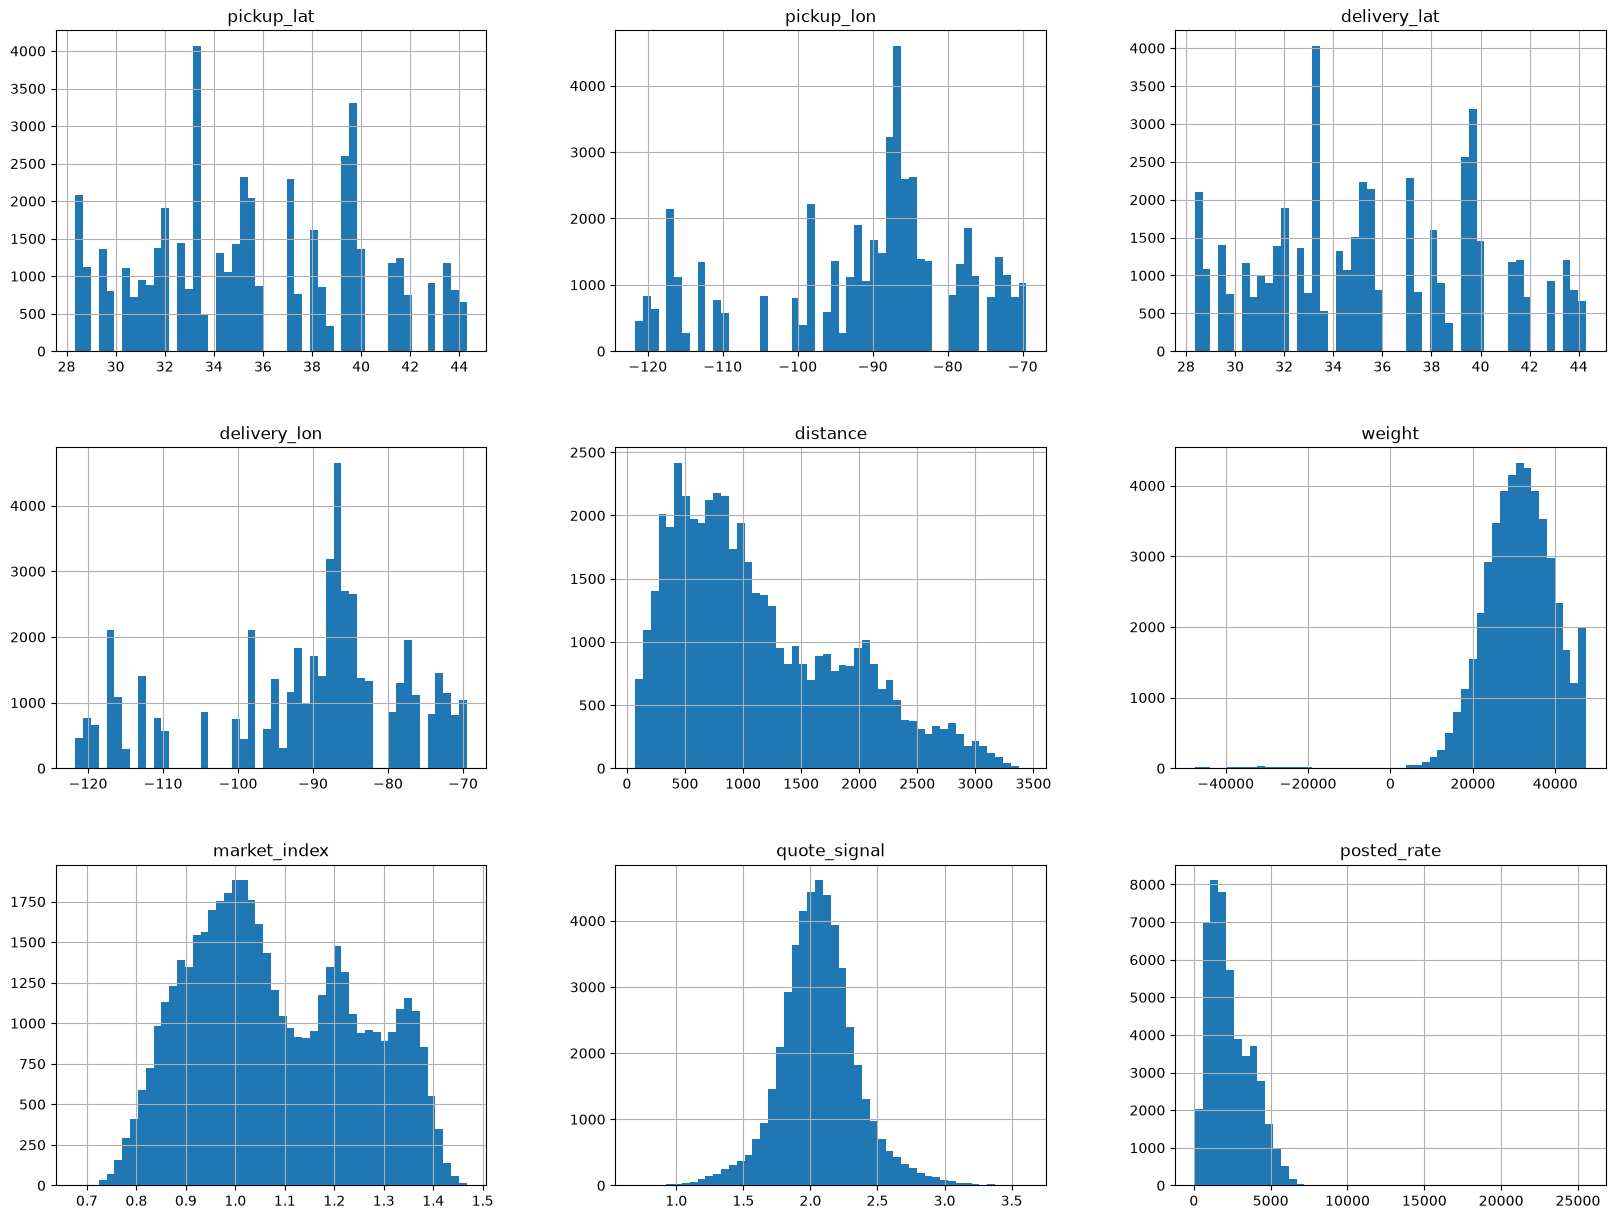

In [6]:
import matplotlib.pyplot as plt
freight.hist(bins=50,figsize=(20,15))
plt.show()

## market index is higly correlated with date

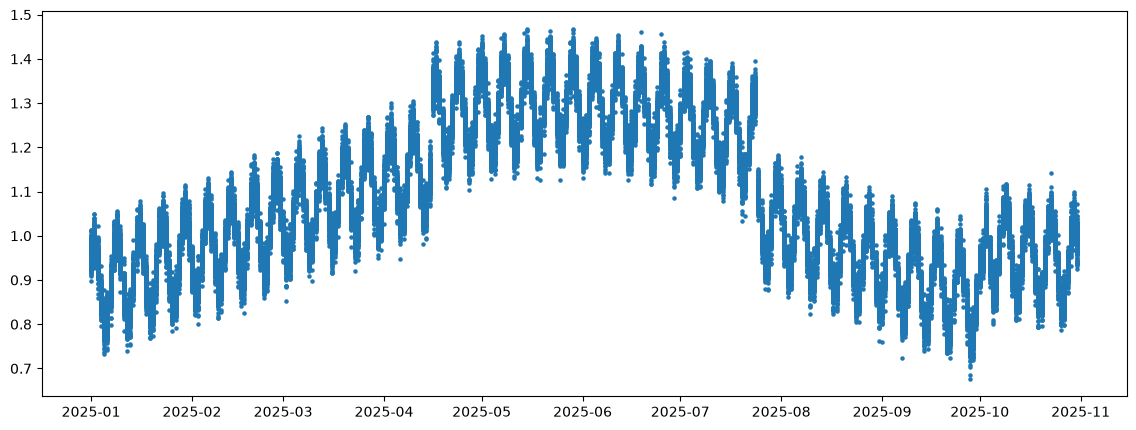

In [7]:
freight["date"] = pd.to_datetime(freight["date"])

plt.figure(figsize=(14,5))
plt.scatter(freight["date"], freight["market_index"], s=5)
plt.show()

## Transforming date into machine readable format

In [8]:
freight["date"] = pd.to_datetime(freight["date"], format="%d-%m-%Y")

freight["month"] = freight["date"].dt.month
freight["day"] = freight["date"].dt.day
freight["weekday"] = freight["date"].dt.weekday
freight["week_of_year"] = freight["date"].dt.isocalendar().week
freight["day_of_year"] = freight["date"].dt.dayofyear

In [9]:
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,month,day,weekday,week_of_year,day_of_year
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,1,1,2,1,1
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,1,1,2,1,1
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,1,1,2,1,1
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28,1,1,2,1,1
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28,1,1,2,1,1


## Drop original date column and invalid negative "weight" rows

In [10]:
freight.drop(columns=["date"], inplace=True)
freight = freight[freight["weight"] >= 0].reset_index(drop=True)

In [11]:
freight.info()

<class 'pandas.DataFrame'>
RangeIndex: 47408 entries, 0 to 47407
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       47408 non-null  str    
 1   pickup        47408 non-null  str    
 2   delivery      47408 non-null  str    
 3   pickup_lat    47408 non-null  float64
 4   pickup_lon    47408 non-null  float64
 5   delivery_lat  47408 non-null  float64
 6   delivery_lon  47408 non-null  float64
 7   distance      47408 non-null  float64
 8   equipment     47408 non-null  str    
 9   weight        47408 non-null  float64
 10  market_index  47038 non-null  float64
 11  quote_signal  47408 non-null  float64
 12  posted_rate   47408 non-null  float64
 13  month         47408 non-null  int32  
 14  day           47408 non-null  int32  
 15  weekday       47408 non-null  int32  
 16  week_of_year  47408 non-null  UInt32 
 17  day_of_year   47408 non-null  int32  
dtypes: UInt32(1), float64(9), int32(4), s

In [12]:
corr_matrix = freight.corr(numeric_only=True)

In [13]:
corr_matrix["posted_rate"].sort_values(ascending=False)

posted_rate     1.000000
distance        0.908552
weight          0.041674
market_index    0.033716
week_of_year    0.024431
day_of_year     0.024362
month           0.023671
day             0.010306
weekday        -0.003314
quote_signal   -0.039820
pickup_lat     -0.090810
delivery_lat   -0.091642
pickup_lon     -0.254386
delivery_lon   -0.257343
Name: posted_rate, dtype: float64

In [14]:
import pandas as pd
import numpy as np

freight["distance_cat"] = pd.cut(
    freight["distance"],
    bins=[0, 250, 500, 750, 1000, 1500, np.inf],
    labels=[1, 2, 3, 4, 5, 6]
)

In [15]:
freight["distance_cat"].value_counts().sort_index()

distance_cat
1     2679
2     7487
3     7551
4     7315
5     8889
6    13487
Name: count, dtype: int64

In [16]:
freight.iloc[2679]

load_id          TR-002725
pickup            Syracuse
delivery        Montgomery
pickup_lat        42.80915
pickup_lon       -76.89973
delivery_lat      31.37602
delivery_lon     -86.10743
distance            1085.4
equipment           Reefer
weight             27834.0
market_index       0.85766
quote_signal        2.0794
posted_rate        2265.13
month                    1
day                     18
weekday                  5
week_of_year             3
day_of_year             18
distance_cat             5
Name: 2679, dtype: object

In [17]:
freight.groupby("distance_cat")["posted_rate"].mean()

distance_cat
1     490.166913
2     937.841941
3    1421.890132
4    1906.605605
5    2584.819096
6    4193.171672
Name: posted_rate, dtype: float64

### Exploratory analysis showed that distance had the strongest linear relationship with posted_rate (r = 0.91). 

### Furthermore, the average freight rate increased monotonically across distance bins. 

### Therefore, stratified sampling based on distance categories was used to preserve the distribution of the most influential feature across training and validation sets.

## Doing Train-Test Split using stratified shuffle split 80-20 %

In [18]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
for train_index,test_index in split.split(freight,freight["distance_cat"]):
                               strat_train_set = freight.iloc[train_index]
                               strat_test_set  = freight.iloc[test_index]

In [19]:
strat_train_set.info()

<class 'pandas.DataFrame'>
Index: 37926 entries, 34953 to 29985
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   load_id       37926 non-null  str     
 1   pickup        37926 non-null  str     
 2   delivery      37926 non-null  str     
 3   pickup_lat    37926 non-null  float64 
 4   pickup_lon    37926 non-null  float64 
 5   delivery_lat  37926 non-null  float64 
 6   delivery_lon  37926 non-null  float64 
 7   distance      37926 non-null  float64 
 8   equipment     37926 non-null  str     
 9   weight        37926 non-null  float64 
 10  market_index  37635 non-null  float64 
 11  quote_signal  37926 non-null  float64 
 12  posted_rate   37926 non-null  float64 
 13  month         37926 non-null  int32   
 14  day           37926 non-null  int32   
 15  weekday       37926 non-null  int32   
 16  week_of_year  37926 non-null  UInt32  
 17  day_of_year   37926 non-null  int32   
 18  distance_cat  3792

In [20]:
strat_test_set.info()

<class 'pandas.DataFrame'>
Index: 9482 entries, 29449 to 13266
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   load_id       9482 non-null   str     
 1   pickup        9482 non-null   str     
 2   delivery      9482 non-null   str     
 3   pickup_lat    9482 non-null   float64 
 4   pickup_lon    9482 non-null   float64 
 5   delivery_lat  9482 non-null   float64 
 6   delivery_lon  9482 non-null   float64 
 7   distance      9482 non-null   float64 
 8   equipment     9482 non-null   str     
 9   weight        9482 non-null   float64 
 10  market_index  9403 non-null   float64 
 11  quote_signal  9482 non-null   float64 
 12  posted_rate   9482 non-null   float64 
 13  month         9482 non-null   int32   
 14  day           9482 non-null   int32   
 15  weekday       9482 non-null   int32   
 16  week_of_year  9482 non-null   UInt32  
 17  day_of_year   9482 non-null   int32   
 18  distance_cat  9482 

## Lets create an copy of train set for data manipulation and understanding so we dont disturb original train set

In [21]:
freight_copy = strat_train_set.copy()

## Drop Target posted_rate and copy it in freight_labels




In [22]:
freight_copy = strat_train_set.drop("posted_rate", axis=1)
y_train = strat_train_set["posted_rate"].copy()

## Using SimpleImputer to fill missing values

In [23]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")

## Before Imputing [We have to drop text features and reinclude them using 1 hot encoder] also remove distance_cat 

In [24]:
freight_num = freight_copy.drop(
    columns=["pickup", "delivery", "equipment", "load_id","distance_cat"]
)
freight_num_dropped = freight_copy[["pickup", "delivery", "equipment"]].copy()
load_id = freight_copy["load_id"].copy()

In [25]:
imputer.fit(freight_num)

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['pickup_lat','pickup_lon','delivery_lat',...,'weekday','week_of_year', 'day_of_year']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](13,)","[ 35.29,-88.09, 35.29,..., 3. , 22. ,151. ]"


In [30]:
def freight_loading_val():
    csv_path="validation.csv"
    return pd.read_csv(csv_path)

In [31]:
freight_val=freight_loading_val()
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [32]:
freight_val.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       12000 non-null  str    
 1   pickup        12000 non-null  str    
 2   delivery      12000 non-null  str    
 3   pickup_lat    12000 non-null  float64
 4   pickup_lon    12000 non-null  float64
 5   delivery_lat  12000 non-null  float64
 6   delivery_lon  12000 non-null  float64
 7   distance      12000 non-null  float64
 8   equipment     12000 non-null  str    
 9   weight        11835 non-null  float64
 10  date          12000 non-null  str    
 11  market_index  11751 non-null  float64
 12  quote_signal  12000 non-null  float64
dtypes: float64(8), str(5)
memory usage: 1.2 MB


In [33]:
%matplotlib inline

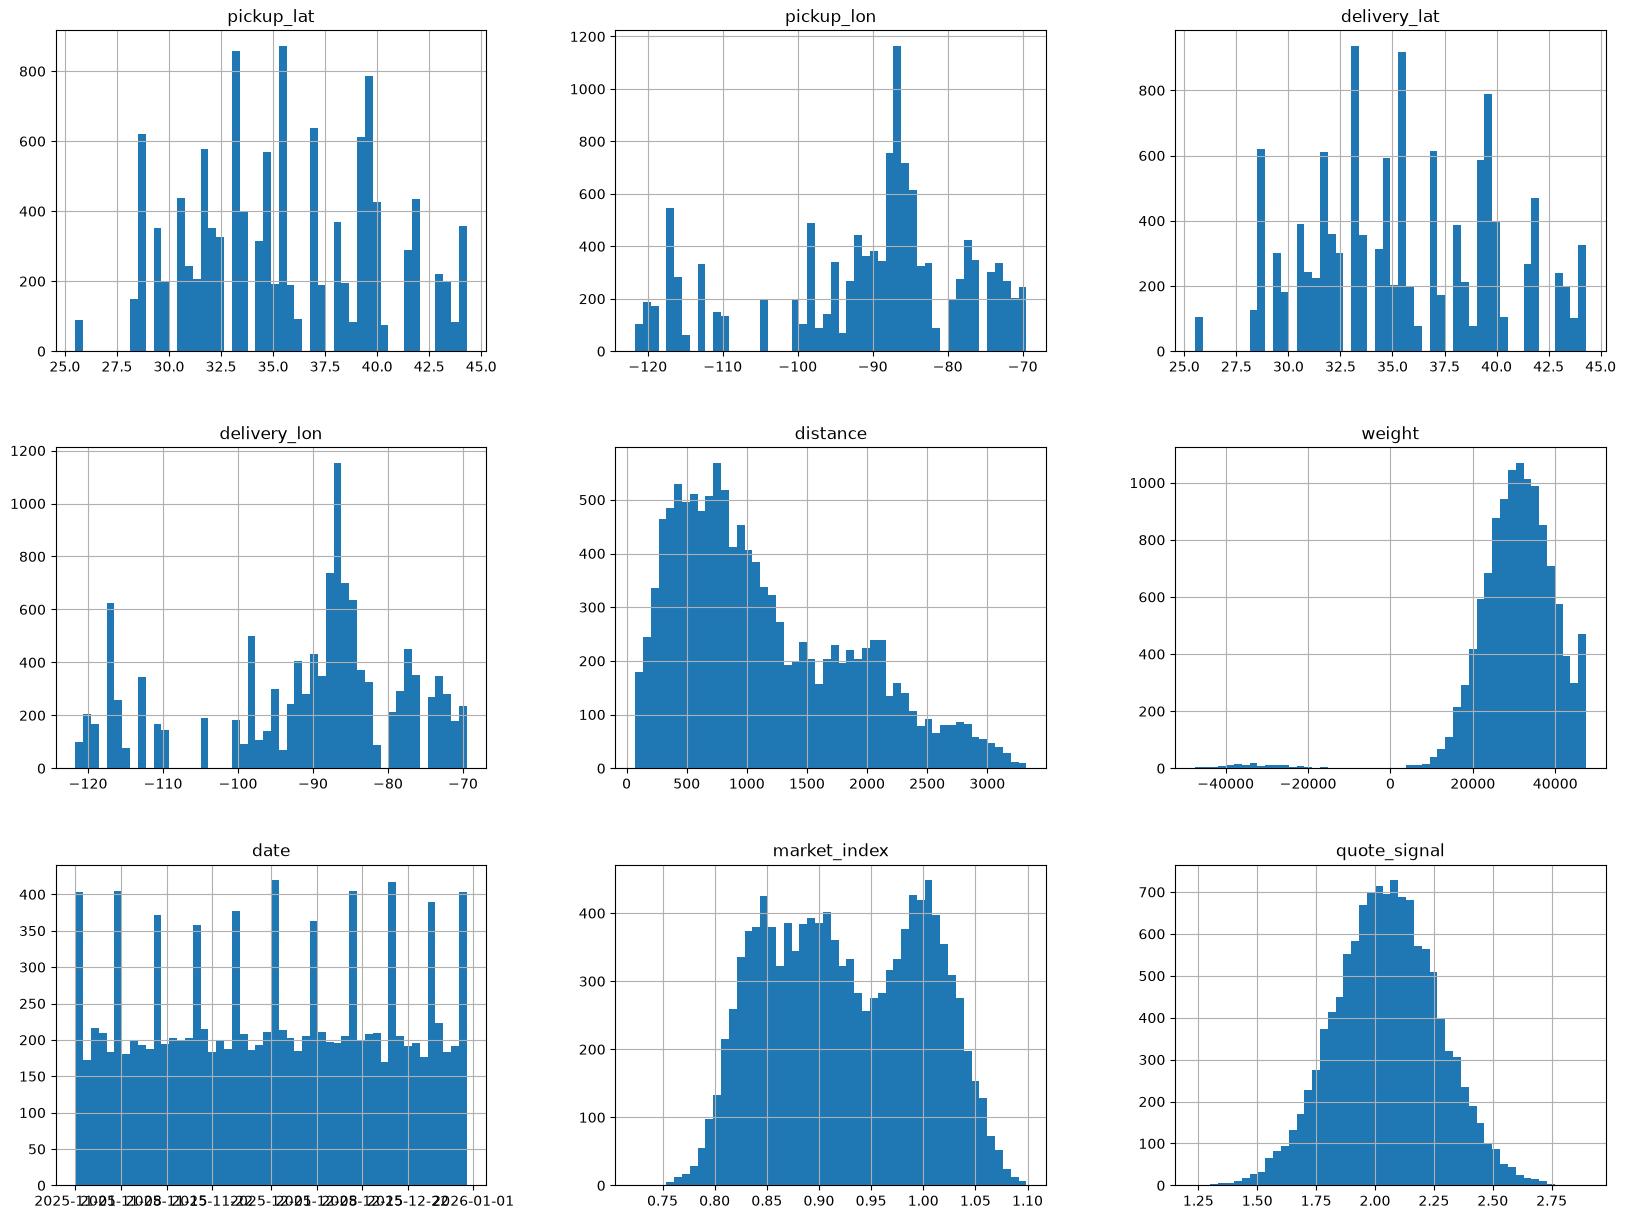

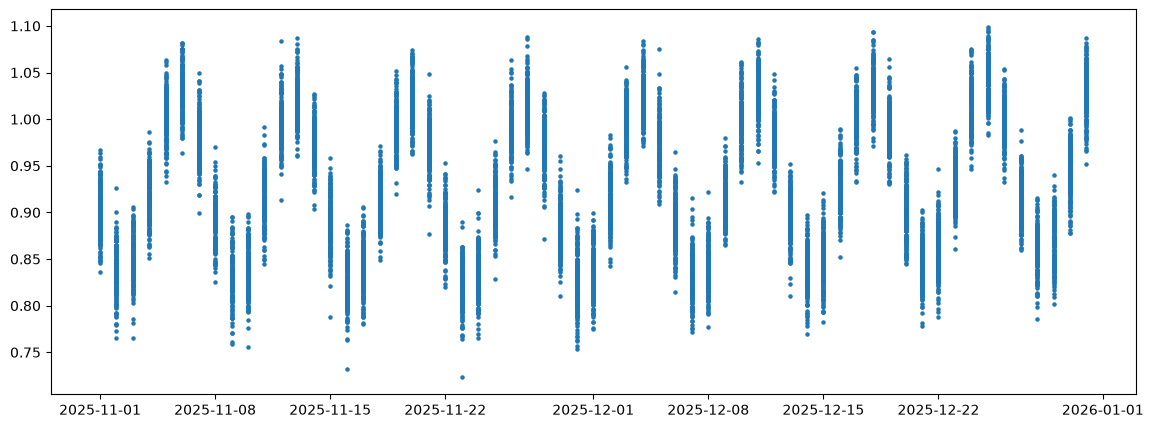

In [50]:
import matplotlib.pyplot as plt
freight.hist(bins=50,figsize=(20,15))
plt.show()

freight["date"] = pd.to_datetime(freight_val["date"])

plt.figure(figsize=(14,5))
plt.scatter(freight_val["date"], freight_val["market_index"], s=5)
plt.show()

freight_val["date"] = pd.to_datetime(freight_val["date"], format="%d-%m-%Y")

freight_val["month"] = freight_val["date"].dt.month
freight_val["day"] = freight_val["date"].dt.day
freight_val["weekday"] = freight_val["date"].dt.weekday
freight_val["week_of_year"] = freight_val["date"].dt.isocalendar().week
freight_val["day_of_year"] = freight_val["date"].dt.dayofyear

In [52]:
freight_val.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,month,day,weekday,week_of_year,day_of_year
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388,11,1,5,44,305
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240,11,1,5,44,305
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480,11,1,5,44,305
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579,11,1,5,44,305
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541,11,1,5,44,305


In [53]:
freight_val.drop(columns=["date"], inplace=True)
freight_val = freight_val[freight_val["weight"] >= 0].reset_index(drop=True)
freight_val.info()

<class 'pandas.DataFrame'>
RangeIndex: 11690 entries, 0 to 11689
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       11690 non-null  str    
 1   pickup        11690 non-null  str    
 2   delivery      11690 non-null  str    
 3   pickup_lat    11690 non-null  float64
 4   pickup_lon    11690 non-null  float64
 5   delivery_lat  11690 non-null  float64
 6   delivery_lon  11690 non-null  float64
 7   distance      11690 non-null  float64
 8   equipment     11690 non-null  str    
 9   weight        11690 non-null  float64
 10  market_index  11446 non-null  float64
 11  quote_signal  11690 non-null  float64
 12  month         11690 non-null  int32  
 13  day           11690 non-null  int32  
 14  weekday       11690 non-null  int32  
 15  week_of_year  11690 non-null  UInt32 
 16  day_of_year   11690 non-null  int32  
dtypes: UInt32(1), float64(8), int32(4), str(4)
memory usage: 1.3 MB


In [56]:
freight_num_val = freight_val.drop(
    columns=["pickup", "delivery", "equipment", "load_id"]
)
freight_num_dropped = freight_val[["pickup", "delivery", "equipment"]].copy()
load_id = freight_val["load_id"].copy()

In [57]:
final_freight_val = imputer.transform(freight_num_val)

In [59]:
final_val = pd.DataFrame(
    final_freight_val,
    columns=freight_num_val.columns,
    index=freight_num_val.index
)

## Verify If data was merged properly or not

In [60]:
final_val.iloc[2683]

pickup_lat         38.16908
pickup_lon        -72.74564
delivery_lat       35.37376
delivery_lon      -77.47605
distance          402.20000
weight          25580.00000
market_index        0.91836
quote_signal        1.98359
month              11.00000
day                15.00000
weekday             5.00000
week_of_year       46.00000
day_of_year       319.00000
Name: 2683, dtype: float64

## Missing Values fixed

In [76]:
final_val.info()

<class 'pandas.DataFrame'>
RangeIndex: 11690 entries, 0 to 11689
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   pickup_lat    11690 non-null  float64
 1   pickup_lon    11690 non-null  float64
 2   delivery_lat  11690 non-null  float64
 3   delivery_lon  11690 non-null  float64
 4   distance      11690 non-null  float64
 5   weight        11690 non-null  float64
 6   market_index  11690 non-null  float64
 7   quote_signal  11690 non-null  float64
 8   month         11690 non-null  float64
 9   day           11690 non-null  float64
 10  weekday       11690 non-null  float64
 11  week_of_year  11690 non-null  float64
 12  day_of_year   11690 non-null  float64
dtypes: float64(13)
memory usage: 1.2 MB


## Handling Text and Catorgory data with One Hot Encoder and ColumnTransformer

In [77]:
import joblib

imputer = joblib.load("imputer.pkl")
encoder = joblib.load("onehot_encoder.pkl")
model = joblib.load("best_xgboost_model.pkl")

encoded_val = encoder.transform(
    freight_num_dropped[["equipment"]]
)

In [78]:
encoded_val = pd.DataFrame(
    encoded_val,
    columns=encoder.get_feature_names_out(),
    index=freight_num_dropped.index
)

In [79]:
encoded_val.head()

,equipment_Dry Van,equipment_Flatbed,equipment_Reefer
0,0.0,1.0,0.0
1,0.0,0.0,1.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0


In [80]:
print(encoded_val.shape)
print(final_val.shape)

(11690, 3)
(11690, 13)


In [81]:
X_val_1hot = pd.concat(
    [final_val, encoded_val],
    axis=1
)

In [82]:
pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("display.width", 1000)

In [83]:
X_val_1hot.loc[[4350]]

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,month,day,weekday,week_of_year,day_of_year,equipment_Dry Van,equipment_Flatbed,equipment_Reefer
4350,35.56802,-89.52871,39.55328,-72.18051,1135.0,7545.0,0.79223,1.93769,11.0,24.0,0.0,48.0,328.0,1.0,0.0,0.0


## Load Model and predict

In [84]:
y_pred_loaded = model.predict(X_val_1hot)

In [87]:
import pandas as pd

# Create results dataframe
results = pd.DataFrame({
    "load_id": load_id,
    "Predicted_Posted_Rate": y_pred_loaded
    
})

# Sort by load_id
results = results.sort_values(by="load_id").reset_index(drop=True)

# Save to CSV
results.to_csv("Validation_XGBoost.csv", index=False)

print(results.head())
print("\nCSV saved successfully as 'Validation_XGBoost.csv'")

     load_id  Predicted_Posted_Rate
0  TE-000001             889.304138
1  TE-000002            5277.725586
2  TE-000003            5507.297852
3  TE-000004            4137.759766
4  TE-000006            4569.821777

CSV saved successfully as 'Validation_XGBoost.csv'
